In [1]:
# ============================================================================
# CELL 1: Import Libraries dan Setup Environment
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Setup untuk PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Check CUDA availability
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA Device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
    device = torch.device("cuda:0")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Matplotlib settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

PyTorch Version: 2.7.1+cu118
CUDA Available: True
CUDA Device: NVIDIA GeForce RTX 3050
CUDA Version: 11.8
Using device: cuda:0


In [2]:
# ============================================================================
# CELL 2: Define Paths
# ============================================================================
# Dataset paths
PATH_FRAUD = r"C:\FRAUD-Sinta2\Data\Kaggle_Fraud"
PATH_OLIST = r"C:\FRAUD-Sinta2\Data\Olist"

# Create output directories
os.makedirs("outputs", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/models", exist_ok=True)
os.makedirs("outputs/data", exist_ok=True)

print("Directories created successfully!")
print(f"Fraud Dataset Path: {PATH_FRAUD}")
print(f"Olist Dataset Path: {PATH_OLIST}")


Directories created successfully!
Fraud Dataset Path: C:\FRAUD-Sinta2\Data\Kaggle_Fraud
Olist Dataset Path: C:\FRAUD-Sinta2\Data\Olist


In [3]:
# ============================================================================
# CELL 3: Load Credit Card Fraud Dataset (Kaggle)
# ============================================================================
print("\n" + "="*80)
print("LOADING CREDIT CARD FRAUD DATASET")
print("="*80)

# Load the dataset
df_fraud = pd.read_csv(os.path.join(PATH_FRAUD, 'creditcard.csv'))

print(f"\nDataset Shape: {df_fraud.shape}")
print(f"\nColumns: {df_fraud.columns.tolist()}")
print(f"\nFirst few rows:")
print(df_fraud.head())

# Check data types
print(f"\nData Types:")
print(df_fraud.dtypes)

# Check missing values
print(f"\nMissing Values:")
print(df_fraud.isnull().sum())

# Basic statistics
print(f"\nBasic Statistics:")
print(df_fraud.describe())


LOADING CREDIT CARD FRAUD DATASET

Dataset Shape: (284807, 31)

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

First few rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672 


FRAUD DATASET - CLASS DISTRIBUTION ANALYSIS

Class Distribution:
Normal Transactions (0): 284,315 (99.8273%)
Fraud Transactions (1): 492 (0.1727%)
Fraud Ratio: 1:577.88


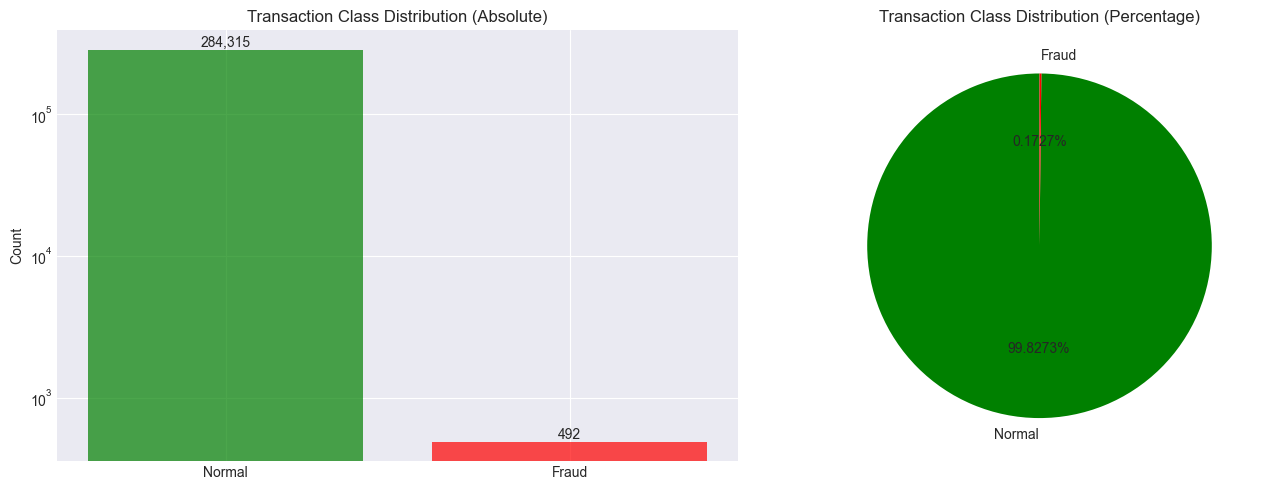

In [4]:
# ============================================================================
# CELL 4: Fraud Dataset - Class Distribution
# ============================================================================
print("\n" + "="*80)
print("FRAUD DATASET - CLASS DISTRIBUTION ANALYSIS")
print("="*80)

# Count fraud vs normal transactions
fraud_counts = df_fraud['Class'].value_counts()
fraud_percentage = df_fraud['Class'].value_counts(normalize=True) * 100

print(f"\nClass Distribution:")
print(f"Normal Transactions (0): {fraud_counts[0]:,} ({fraud_percentage[0]:.4f}%)")
print(f"Fraud Transactions (1): {fraud_counts[1]:,} ({fraud_percentage[1]:.4f}%)")
print(f"Fraud Ratio: 1:{fraud_counts[0]/fraud_counts[1]:.2f}")

# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
axes[0].bar(['Normal', 'Fraud'], fraud_counts.values, color=['green', 'red'], alpha=0.7)
axes[0].set_ylabel('Count')
axes[0].set_title('Transaction Class Distribution (Absolute)')
axes[0].set_yscale('log')
for i, (label, count) in enumerate(zip(['Normal', 'Fraud'], fraud_counts.values)):
    axes[0].text(i, count, f'{count:,}', ha='center', va='bottom')

# Percentage plot
axes[1].pie(fraud_counts.values, labels=['Normal', 'Fraud'], autopct='%1.4f%%',
            colors=['green', 'red'], startangle=90)
axes[1].set_title('Transaction Class Distribution (Percentage)')

plt.tight_layout()
plt.savefig('outputs/figures/01_fraud_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()



FRAUD DATASET - AMOUNT DISTRIBUTION

Amount Statistics by Class:
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


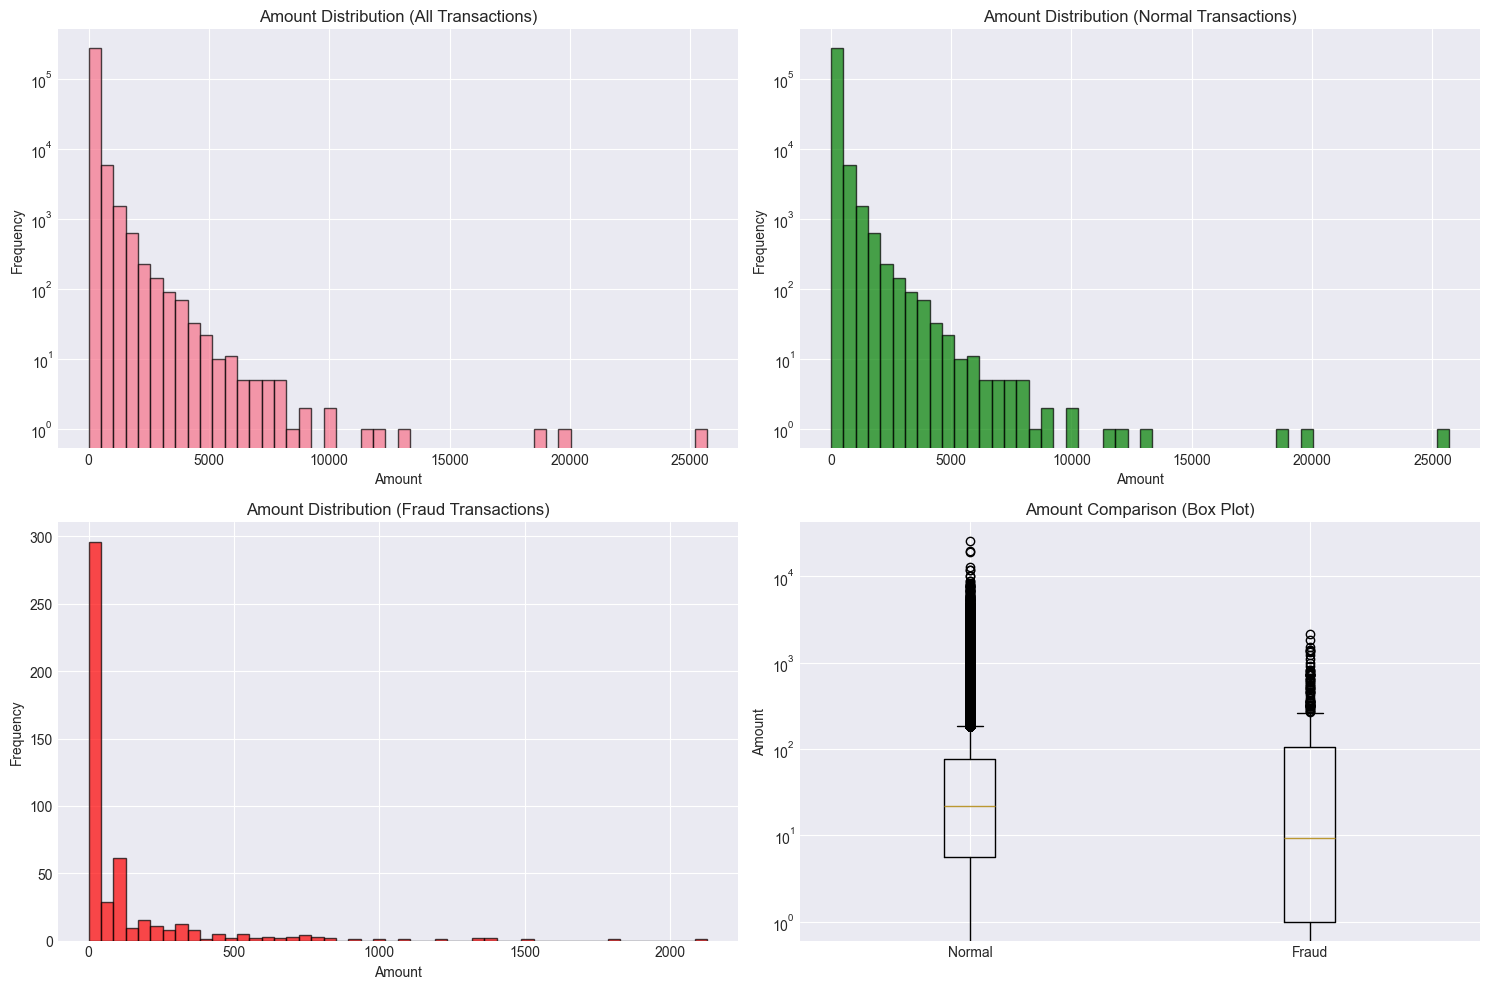

In [5]:
# ============================================================================
# CELL 5: Fraud Dataset - Amount Distribution
# ============================================================================
print("\n" + "="*80)
print("FRAUD DATASET - AMOUNT DISTRIBUTION")
print("="*80)

# Statistics for Amount by class
print("\nAmount Statistics by Class:")
print(df_fraud.groupby('Class')['Amount'].describe())

# Visualize amount distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# All transactions
axes[0, 0].hist(df_fraud['Amount'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Amount')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Amount Distribution (All Transactions)')
axes[0, 0].set_yscale('log')

# Normal transactions
normal_amounts = df_fraud[df_fraud['Class'] == 0]['Amount']
axes[0, 1].hist(normal_amounts, bins=50, color='green', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Amount')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Amount Distribution (Normal Transactions)')
axes[0, 1].set_yscale('log')

# Fraud transactions
fraud_amounts = df_fraud[df_fraud['Class'] == 1]['Amount']
axes[1, 0].hist(fraud_amounts, bins=50, color='red', edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Amount')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Amount Distribution (Fraud Transactions)')

# Box plot comparison
axes[1, 1].boxplot([normal_amounts, fraud_amounts], labels=['Normal', 'Fraud'])
axes[1, 1].set_ylabel('Amount')
axes[1, 1].set_title('Amount Comparison (Box Plot)')
axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.savefig('outputs/figures/02_fraud_amount_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


FRAUD DATASET - TIME DISTRIBUTION

Time Statistics:
Total Duration: 48.00 hours
Min Time: 0.0 seconds
Max Time: 172792.0 seconds


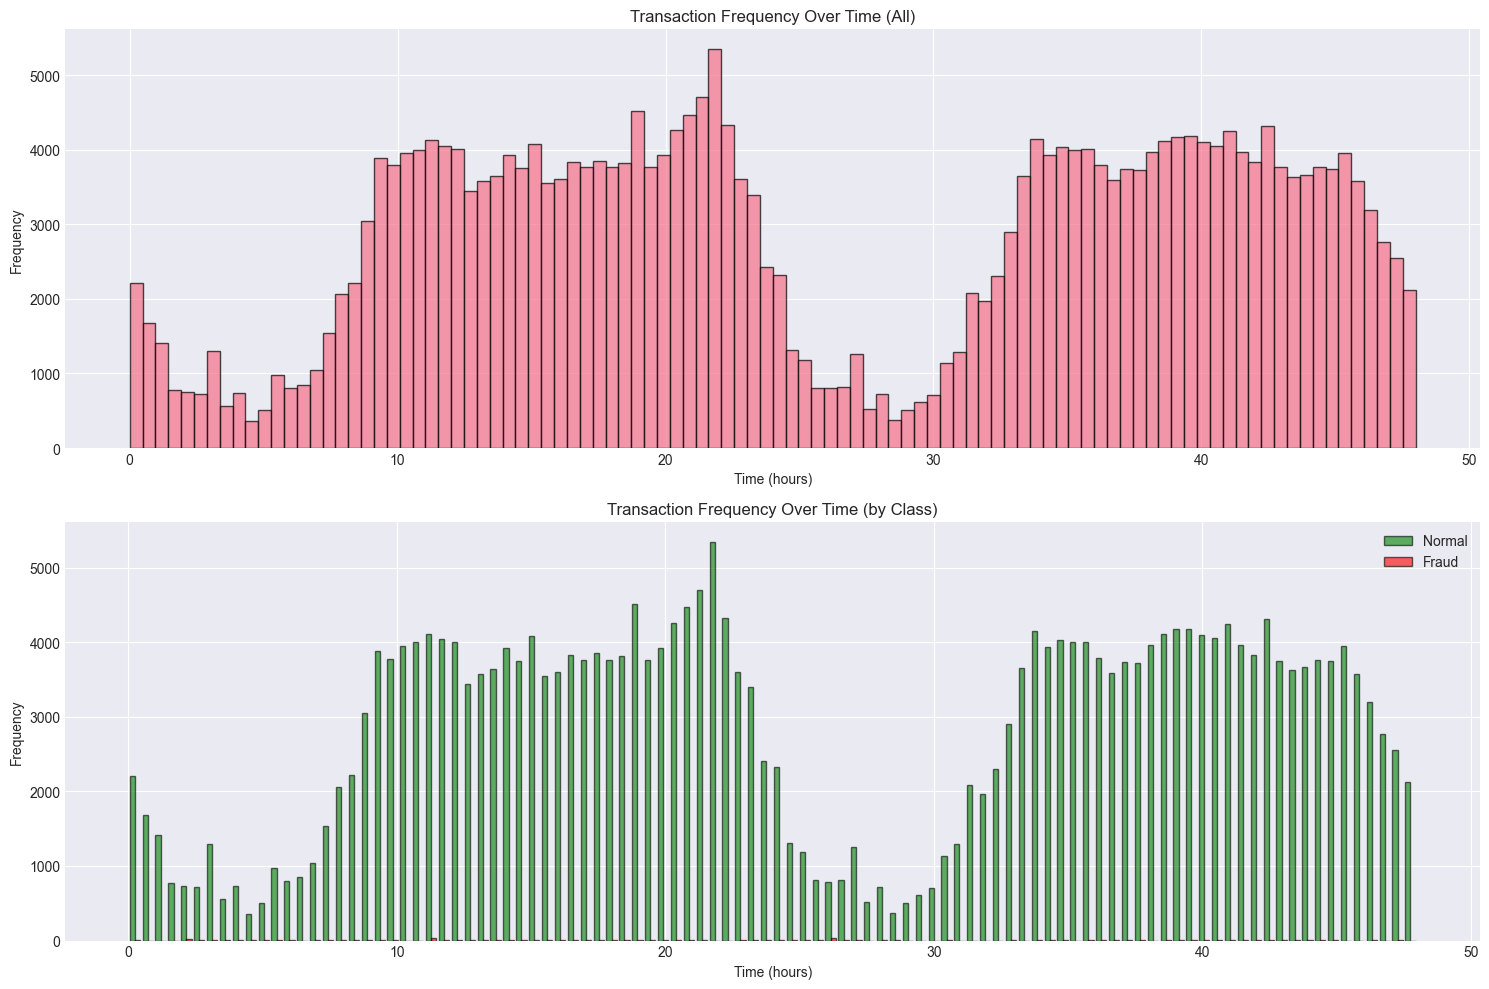

In [6]:
# ============================================================================
# CELL 6: Fraud Dataset - Time Distribution
# ============================================================================
print("\n" + "="*80)
print("FRAUD DATASET - TIME DISTRIBUTION")
print("="*80)

# Convert Time to hours
df_fraud['Time_hours'] = df_fraud['Time'] / 3600

print("\nTime Statistics:")
print(f"Total Duration: {df_fraud['Time'].max() / 3600:.2f} hours")
print(f"Min Time: {df_fraud['Time'].min()} seconds")
print(f"Max Time: {df_fraud['Time'].max()} seconds")

# Visualize time distribution
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# All transactions over time
axes[0].hist(df_fraud['Time_hours'], bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Time (hours)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Transaction Frequency Over Time (All)')

# Fraud vs Normal over time
axes[1].hist([df_fraud[df_fraud['Class'] == 0]['Time_hours'],
              df_fraud[df_fraud['Class'] == 1]['Time_hours']],
             bins=100, label=['Normal', 'Fraud'], color=['green', 'red'],
             alpha=0.6, edgecolor='black')
axes[1].set_xlabel('Time (hours)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Transaction Frequency Over Time (by Class)')
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/figures/03_fraud_time_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
# ============================================================================
# CELL 7: Load Olist E-Commerce Dataset
# ============================================================================
print("\n" + "="*80)
print("LOADING OLIST E-COMMERCE DATASET")
print("="*80)

# List all CSV files in Olist directory
olist_files = [f for f in os.listdir(PATH_OLIST) if f.endswith('.csv')]
print(f"\nAvailable files in Olist directory:")
for file in olist_files:
    print(f"  - {file}")

# Load main datasets
df_orders = pd.read_csv(os.path.join(PATH_OLIST, 'olist_orders_dataset.csv'))
df_order_items = pd.read_csv(os.path.join(PATH_OLIST, 'olist_order_items_dataset.csv'))
df_order_payments = pd.read_csv(os.path.join(PATH_OLIST, 'olist_order_payments_dataset.csv'))
df_customers = pd.read_csv(os.path.join(PATH_OLIST, 'olist_customers_dataset.csv'))
df_products = pd.read_csv(os.path.join(PATH_OLIST, 'olist_products_dataset.csv'))

print(f"\nOrders Shape: {df_orders.shape}")
print(f"Order Items Shape: {df_order_items.shape}")
print(f"Order Payments Shape: {df_order_payments.shape}")
print(f"Customers Shape: {df_customers.shape}")
print(f"Products Shape: {df_products.shape}")



LOADING OLIST E-COMMERCE DATASET

Available files in Olist directory:
  - olist_customers_dataset.csv
  - olist_geolocation_dataset.csv
  - olist_orders_dataset.csv
  - olist_order_items_dataset.csv
  - olist_order_payments_dataset.csv
  - olist_order_reviews_dataset.csv
  - olist_products_dataset.csv
  - olist_sellers_dataset.csv
  - product_category_name_translation.csv

Orders Shape: (99441, 8)
Order Items Shape: (112650, 7)
Order Payments Shape: (103886, 5)
Customers Shape: (99441, 5)
Products Shape: (32951, 9)


In [8]:
# ============================================================================
# CELL 8: Olist Dataset - Basic Info
# ============================================================================
print("\n" + "="*80)
print("OLIST DATASET - BASIC INFORMATION")
print("="*80)

print("\n--- ORDERS DATASET ---")
print(df_orders.head())
print(f"\nColumns: {df_orders.columns.tolist()}")
print(f"\nMissing Values:")
print(df_orders.isnull().sum())

print("\n--- ORDER ITEMS DATASET ---")
print(df_order_items.head())
print(f"\nColumns: {df_order_items.columns.tolist()}")

print("\n--- ORDER PAYMENTS DATASET ---")
print(df_order_payments.head())
print(f"\nColumns: {df_order_payments.columns.tolist()}")


OLIST DATASET - BASIC INFORMATION

--- ORDERS DATASET ---
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 2

In [9]:
# ============================================================================
# CELL 9: Merge Olist Datasets
# ============================================================================
print("\n" + "="*80)
print("MERGING OLIST DATASETS")
print("="*80)

# Merge orders with order items
df_olist_merged = df_orders.merge(df_order_items, on='order_id', how='inner')
print(f"After merging orders with items: {df_olist_merged.shape}")

# Merge with payments
df_olist_merged = df_olist_merged.merge(df_order_payments, on='order_id', how='inner')
print(f"After merging with payments: {df_olist_merged.shape}")

# Merge with customers
df_olist_merged = df_olist_merged.merge(df_customers, on='customer_id', how='inner')
print(f"After merging with customers: {df_olist_merged.shape}")

# Merge with products
df_olist_merged = df_olist_merged.merge(df_products, on='product_id', how='left')
print(f"After merging with products: {df_olist_merged.shape}")

print(f"\nMerged dataset columns: {df_olist_merged.columns.tolist()}")
print(f"\nFirst few rows:")
print(df_olist_merged.head())


MERGING OLIST DATASETS
After merging orders with items: (112650, 14)
After merging with payments: (117601, 18)
After merging with customers: (117601, 22)
After merging with products: (117601, 30)

Merged dataset columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

First few rows:
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76

In [10]:
# ============================================================================
# CELL 10: Olist Dataset - Feature Selection and Cleaning
# ============================================================================
print("\n" + "="*80)
print("OLIST DATASET - FEATURE SELECTION AND CLEANING")
print("="*80)

# Select relevant columns for transaction analysis
selected_columns = [
    'order_id',
    'customer_id',
    'customer_unique_id',
    'order_purchase_timestamp',
    'order_status',
    'price',
    'freight_value',
    'payment_type',
    'payment_value',
    'payment_installments',
    'customer_city',
    'customer_state',
    'product_category_name'
]

# Filter columns that exist
selected_columns = [col for col in selected_columns if col in df_olist_merged.columns]
df_olist = df_olist_merged[selected_columns].copy()

print(f"Selected columns: {selected_columns}")
print(f"\nShape after selection: {df_olist.shape}")

# Remove rows with missing critical values
print(f"\nMissing values before cleaning:")
print(df_olist.isnull().sum())

# Keep only delivered orders
if 'order_status' in df_olist.columns:
    df_olist = df_olist[df_olist['order_status'] == 'delivered'].copy()
    print(f"\nShape after filtering delivered orders: {df_olist.shape}")

# Remove rows with missing payment_value or price
df_olist = df_olist.dropna(subset=['payment_value', 'price'])
print(f"Shape after removing missing payment/price: {df_olist.shape}")

# Convert timestamp to datetime
df_olist['order_purchase_timestamp'] = pd.to_datetime(df_olist['order_purchase_timestamp'])

# Sort by timestamp
df_olist = df_olist.sort_values('order_purchase_timestamp').reset_index(drop=True)

print(f"\nFinal cleaned Olist dataset shape: {df_olist.shape}")
print(df_olist.head())



OLIST DATASET - FEATURE SELECTION AND CLEANING
Selected columns: ['order_id', 'customer_id', 'customer_unique_id', 'order_purchase_timestamp', 'order_status', 'price', 'freight_value', 'payment_type', 'payment_value', 'payment_installments', 'customer_city', 'customer_state', 'product_category_name']

Shape after selection: (117601, 13)

Missing values before cleaning:
order_id                       0
customer_id                    0
customer_unique_id             0
order_purchase_timestamp       0
order_status                   0
price                          0
freight_value                  0
payment_type                   0
payment_value                  0
payment_installments           0
customer_city                  0
customer_state                 0
product_category_name       1698
dtype: int64

Shape after filtering delivered orders: (115035, 13)
Shape after removing missing payment/price: (115035, 13)

Final cleaned Olist dataset shape: (115035, 13)
                         


OLIST DATASET - PAYMENT DISTRIBUTION

Payment Value Statistics:
count    115035.000000
mean        171.914291
std         266.108823
min           0.000000
25%          60.850000
50%         108.190000
75%         188.940000
max       13664.080000
Name: payment_value, dtype: float64

Payment Type Distribution:
payment_type
credit_card    84896
boleto         22362
voucher         6123
debit_card      1654
Name: count, dtype: int64


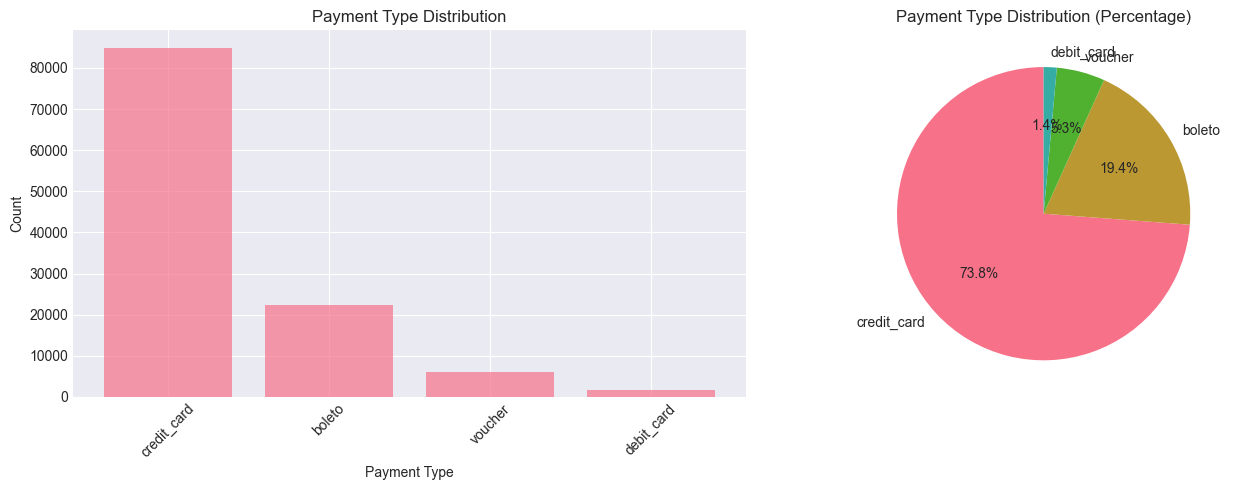

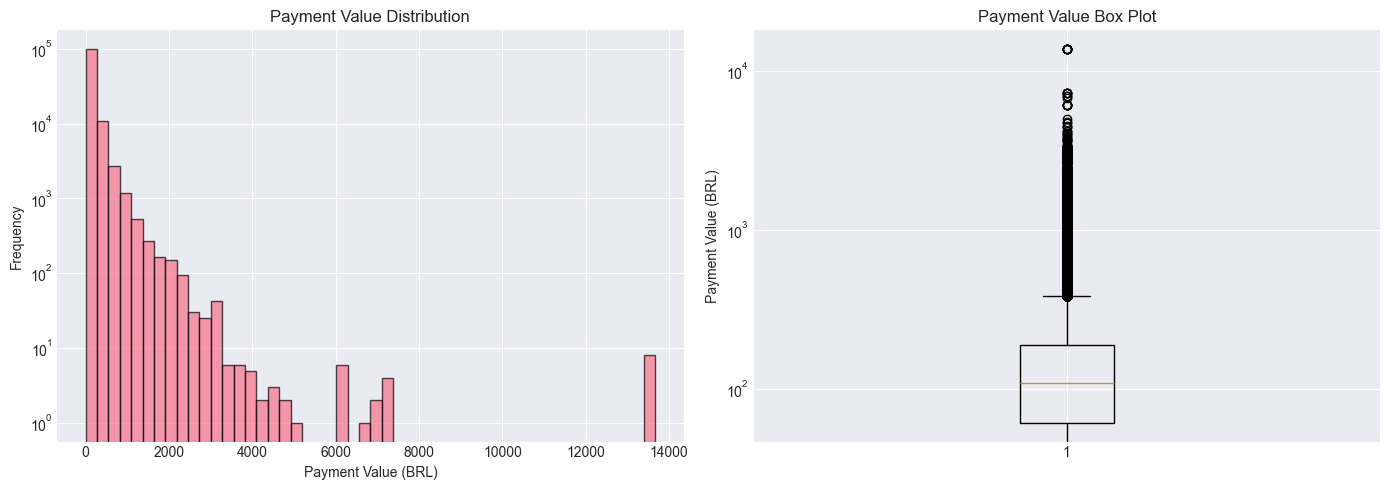

In [11]:
# ============================================================================
# CELL 11: Olist Dataset - Payment Distribution
# ============================================================================
print("\n" + "="*80)
print("OLIST DATASET - PAYMENT DISTRIBUTION")
print("="*80)

# Payment statistics
print("\nPayment Value Statistics:")
print(df_olist['payment_value'].describe())

# Payment type distribution
if 'payment_type' in df_olist.columns:
    print("\nPayment Type Distribution:")
    print(df_olist['payment_type'].value_counts())
    
    # Visualize payment types
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    payment_counts = df_olist['payment_type'].value_counts()
    axes[0].bar(payment_counts.index, payment_counts.values, alpha=0.7)
    axes[0].set_xlabel('Payment Type')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Payment Type Distribution')
    axes[0].tick_params(axis='x', rotation=45)
    
    axes[1].pie(payment_counts.values, labels=payment_counts.index, autopct='%1.1f%%',
                startangle=90)
    axes[1].set_title('Payment Type Distribution (Percentage)')
    
    plt.tight_layout()
    plt.savefig('outputs/figures/04_olist_payment_types.png', dpi=300, bbox_inches='tight')
    plt.show()

# Visualize payment value distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_olist['payment_value'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Payment Value (BRL)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Payment Value Distribution')
axes[0].set_yscale('log')

axes[1].boxplot(df_olist['payment_value'])
axes[1].set_ylabel('Payment Value (BRL)')
axes[1].set_title('Payment Value Box Plot')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig('outputs/figures/05_olist_payment_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


OLIST DATASET - TEMPORAL ANALYSIS

Time Range:
Start: 2016-10-03 09:44:50
End: 2018-08-29 15:00:37
Duration: 695 days


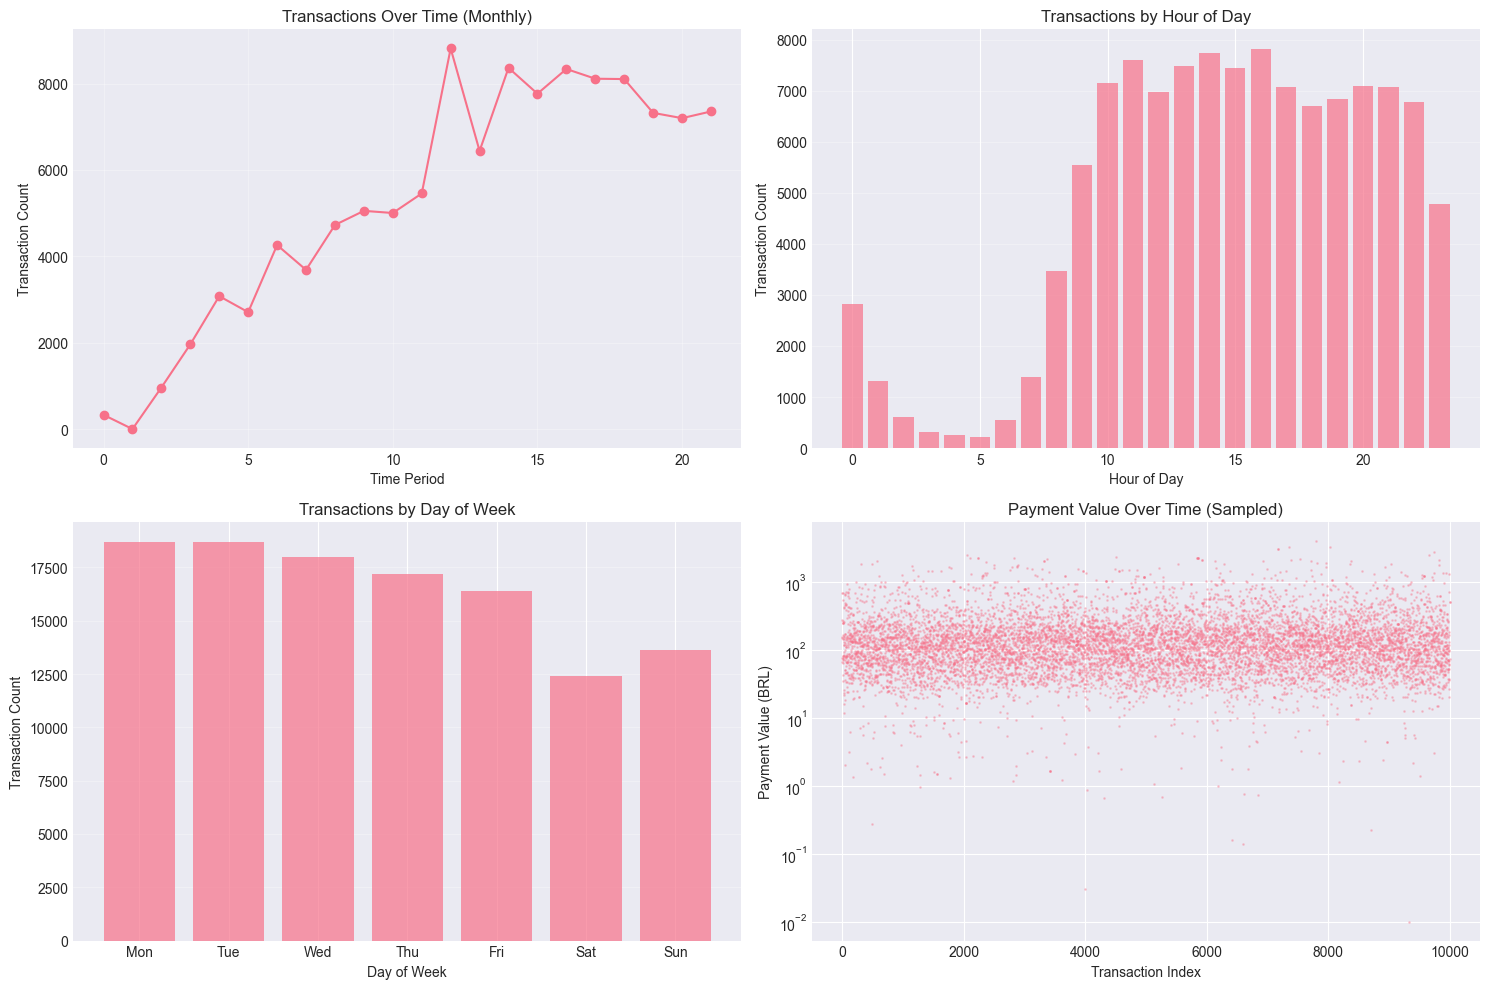

In [12]:
# ============================================================================
# CELL 12: Olist Dataset - Temporal Analysis
# ============================================================================
print("\n" + "="*80)
print("OLIST DATASET - TEMPORAL ANALYSIS")
print("="*80)

# Extract time features
df_olist['year'] = df_olist['order_purchase_timestamp'].dt.year
df_olist['month'] = df_olist['order_purchase_timestamp'].dt.month
df_olist['day'] = df_olist['order_purchase_timestamp'].dt.day
df_olist['hour'] = df_olist['order_purchase_timestamp'].dt.hour
df_olist['dayofweek'] = df_olist['order_purchase_timestamp'].dt.dayofweek

print("\nTime Range:")
print(f"Start: {df_olist['order_purchase_timestamp'].min()}")
print(f"End: {df_olist['order_purchase_timestamp'].max()}")
print(f"Duration: {(df_olist['order_purchase_timestamp'].max() - df_olist['order_purchase_timestamp'].min()).days} days")

# Visualize temporal patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Transactions by month
monthly_counts = df_olist.groupby(['year', 'month']).size()
axes[0, 0].plot(range(len(monthly_counts)), monthly_counts.values, marker='o')
axes[0, 0].set_xlabel('Time Period')
axes[0, 0].set_ylabel('Transaction Count')
axes[0, 0].set_title('Transactions Over Time (Monthly)')
axes[0, 0].grid(True, alpha=0.3)

# Transactions by hour
hourly_counts = df_olist['hour'].value_counts().sort_index()
axes[0, 1].bar(hourly_counts.index, hourly_counts.values, alpha=0.7)
axes[0, 1].set_xlabel('Hour of Day')
axes[0, 1].set_ylabel('Transaction Count')
axes[0, 1].set_title('Transactions by Hour of Day')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Transactions by day of week
dow_counts = df_olist['dayofweek'].value_counts().sort_index()
dow_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
axes[1, 0].bar(range(7), [dow_counts.get(i, 0) for i in range(7)], alpha=0.7)
axes[1, 0].set_xticks(range(7))
axes[1, 0].set_xticklabels(dow_labels)
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('Transaction Count')
axes[1, 0].set_title('Transactions by Day of Week')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Payment value over time (sampled)
if len(df_olist) > 10000:
    sample_df = df_olist.sample(10000).sort_values('order_purchase_timestamp')
else:
    sample_df = df_olist
axes[1, 1].scatter(range(len(sample_df)), sample_df['payment_value'].values, 
                   alpha=0.3, s=1)
axes[1, 1].set_xlabel('Transaction Index')
axes[1, 1].set_ylabel('Payment Value (BRL)')
axes[1, 1].set_title('Payment Value Over Time (Sampled)')
axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.savefig('outputs/figures/06_olist_temporal_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
# ============================================================================
# CELL 13: Save Cleaned Datasets
# ============================================================================
print("\n" + "="*80)
print("SAVING CLEANED DATASETS")
print("="*80)

# Save fraud dataset
df_fraud.to_csv('outputs/data/fraud_cleaned.csv', index=False)
print(f"Saved fraud dataset: {df_fraud.shape}")

# Save olist dataset
df_olist.to_csv('outputs/data/olist_cleaned.csv', index=False)
print(f"Saved olist dataset: {df_olist.shape}")

print("\n✓ All datasets saved successfully!")



SAVING CLEANED DATASETS
Saved fraud dataset: (284807, 32)
Saved olist dataset: (115035, 18)

✓ All datasets saved successfully!


In [14]:
# ============================================================================
# CELL 14: Summary Statistics
# ============================================================================
print("\n" + "="*80)
print("SUMMARY STATISTICS")
print("="*80)

summary = {
    'Dataset': ['Credit Card Fraud', 'Olist E-Commerce'],
    'Total Transactions': [len(df_fraud), len(df_olist)],
    'Features': [df_fraud.shape[1], df_olist.shape[1]],
    'Time Range': [
        f"{df_fraud['Time'].max() / 3600:.1f} hours",
        f"{(df_olist['order_purchase_timestamp'].max() - df_olist['order_purchase_timestamp'].min()).days} days"
    ],
    'Fraud Ratio': [
        f"{fraud_percentage[1]:.4f}%",
        "To be injected"
    ]
}

df_summary = pd.DataFrame(summary)
print("\n", df_summary.to_string(index=False))

print("\n" + "="*80)
print("EXPLORATORY DATA ANALYSIS COMPLETED!")
print("="*80)
print("\nNext steps:")
print("1. Run Notebook 2 for preprocessing and feature engineering")
print("2. Create anomaly injection for Olist dataset")
print("3. Prepare data for model training")


SUMMARY STATISTICS

           Dataset  Total Transactions  Features Time Range    Fraud Ratio
Credit Card Fraud              284807        32 48.0 hours        0.1727%
 Olist E-Commerce              115035        18   695 days To be injected

EXPLORATORY DATA ANALYSIS COMPLETED!

Next steps:
1. Run Notebook 2 for preprocessing and feature engineering
2. Create anomaly injection for Olist dataset
3. Prepare data for model training
